### Here as you can see the gradient descent is figuring out our optimal alpha construction. where alpha = threshold.

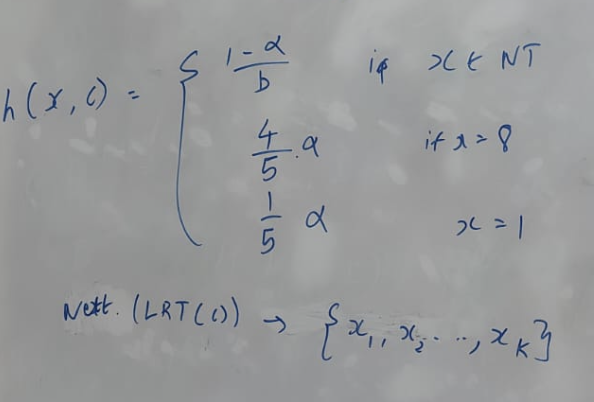

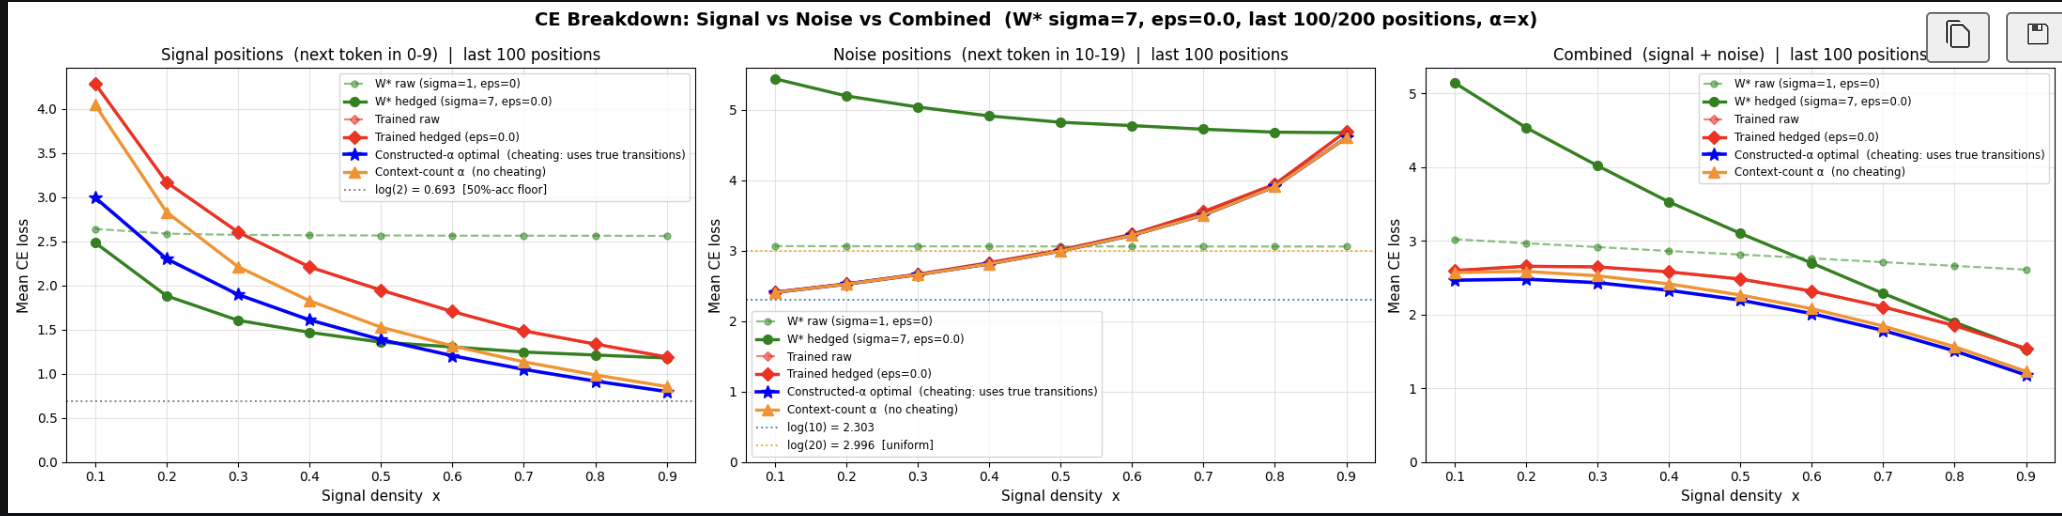

### I can't find a way to construct weights to perfrom even as good as green model with lesser D-model. so training again a model with gradient descent with D-model = 220(same as our previous contruction to compare)

In [4]:

# ── SETTINGS ──────────────────────────────────────────────────────────────────
DATA_DIR    = 'dataset'
MODELS_DIR  = 'models'
DEVICE      = 'cuda:3'

N_SEQS      = 200         # sequences per split used for CE evaluation
TOKEN_START = 100         # evaluate CE on tokens 100–200 (last half, seq_len=200)
TOKEN_END   = 200
WS_SIGMA    = 5.5         # temperature scale on W* logits
ATTN_DIM    = 220          # must match train.py attn_dim
# ──────────────────────────────────────────────────────────────────────────────

import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device(DEVICE)

# ── Trained model (DisentangledTransformer, must match train.py) ──────────────
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores = scores + mask
        attn_out = self.W_o(torch.bmm(F.softmax(scores, dim=-1), V))
        return torch.cat([x, attn_out], dim=-1), scores

class DisentangledTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, bias=False):
        super().__init__()
        self.total_vocab = total_vocab
        self.seq_len     = seq_len
        self.initial_dim = total_vocab + seq_len
        self.layer1 = ConcatAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * attn_dim, total_vocab, bias=bias)
    def forward(self, x, return_attn=False):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, a1 = self.layer1(s, mask)
        s, a2 = self.layer2(s, mask)
        return (self.fc_out(s), [a1, a2]) if return_attn else self.fc_out(s)

# ── PerfectInductionTransformer W* (seq_len=200 matches hand construction) ────
class _ConcatAttn(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        s = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: s = s + mask
        return torch.cat([x, self.W_o(torch.bmm(F.softmax(s, dim=-1), V))], dim=-1)

class PerfectInductionTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, vocab_set1):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len; self.vocab_set1 = vocab_set1
        self.initial_dim = total_vocab + seq_len; self.attn_dim = self.initial_dim
        self.layer1 = _ConcatAttn(self.initial_dim, self.attn_dim)
        self.layer2 = _ConcatAttn(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, total_vocab, bias=False)
        self._set_weights()
    def _set_weights(self):
        V = self.total_vocab; T = self.seq_len; D = self.attn_dim; V_r = self.vocab_set1
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        T1 = torch.zeros(D, D)
        for k in range(V_r, V): T1[k, :] = -1e9
        for tq in range(T):
            for tk in range(T):
                T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
        self.layer1.W_k.weight.data = T1.t()
        Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
        self.layer1.W_v.weight.data = Wv1
        self.layer1.W_o.weight.data = torch.eye(D)
        in2 = D + D
        Wq2 = torch.zeros(D, in2)
        Wq2[:V_r, :V_r]    = torch.eye(V_r) * (D ** 0.5) * 1000.0
        Wq2[:V_r, D:D+V_r] = torch.eye(V_r) * (D ** 0.5) * 50.0
        for v in range(V): Wq2[V_r, v] = (D ** 0.5) * 10.0
        self.layer2.W_q.weight.data = Wq2
        Wk2 = torch.zeros(D, in2); Wk2[:V, D:D+V] = torch.eye(V)
        for v in range(V_r, V): Wk2[V_r, v] = -50000.0
        self.layer2.W_k.weight.data = Wk2
        Wv2 = torch.zeros(D, in2); Wv2[:V, :V] = torch.eye(V)
        self.layer2.W_v.weight.data = Wv2
        self.layer2.W_o.weight.data = torch.eye(D)
        Wfc = torch.zeros(V, in2 + D); Wfc[:V, in2:in2+V] = torch.eye(V)
        self.fc_out.weight.data = Wfc
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s = self.layer1(s, mask); s = self.layer2(s, mask)
        return self.fc_out(s)

# ── Helpers ───────────────────────────────────────────────────────────────────
def load_data(split, thr, n_cap=N_SEQS):
    blob = torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)
    N    = min(n_cap, blob['x'].shape[0])
    blob['x'] = blob['x'][:N]; blob['y'] = blob['y'][:N]
    if 'transitions' in blob: blob['transitions'] = blob['transitions'][:N]
    return blob['x'], blob['y'], int(blob['seq_len']), int(blob['total_vocab']), blob

def load_model(thr, seq_len, total_vocab):
    attn_dim = ATTN_DIM
    model = DisentangledTransformer(total_vocab, seq_len, attn_dim, bias=True).to(device)
    model.load_state_dict(torch.load(os.path.join(MODELS_DIR, f'model_x_{thr}.pth'),
                                     map_location=device, weights_only=True))
    model.eval(); return model

@torch.no_grad()
def compute_ce(model, x, y, total_vocab, batch_size=256):
    total_loss, n_tokens = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(device); yb = y[i:i+batch_size].to(device)
        logits = model(xb)[:, TOKEN_START:TOKEN_END, :]
        yb_w   = yb[:, TOKEN_START:TOKEN_END]
        total_loss += F.cross_entropy(logits.reshape(-1, total_vocab),
                                      yb_w.reshape(-1), reduction='sum').item()
        n_tokens += yb_w.numel()
    return total_loss / n_tokens

@torch.no_grad()
def wstar_ce(blob, sigma=WS_SIGMA, batch_size=128):
    x = blob['x']; y = blob['y']
    V = int(blob['total_vocab']); T = int(blob['seq_len'])
    model = PerfectInductionTransformer(V, T, int(blob['vocab_set1'])).to(device).eval()
    total_loss, n_tok = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(device); yb = y[i:i+batch_size].to(device)
        logits = model(xb)[:, TOKEN_START:TOKEN_END, :] * sigma
        yb_w   = yb[:, TOKEN_START:TOKEN_END]
        total_loss += F.cross_entropy(logits.reshape(-1, V), yb_w.reshape(-1), reduction='sum').item()
        n_tok += yb_w.numel()
    del model
    if device.type == 'cuda': torch.cuda.empty_cache()
    return total_loss / n_tok

def alpha_ce(blob, alpha):
    x_np = blob['x'].numpy(); y_np = blob['y'].numpy()
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]
    trans_counts = np.zeros((B, V, V_sig), dtype=np.float64)
    pending      = np.zeros((B, V), dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok_col = x_np[:, col]; is_ruled = tok_col < V_sig
        ri = np.where(is_ruled)[0]
        if len(ri):
            rt = tok_col[ri]
            oh = (np.arange(V_sig) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_ruled)[0]
        if len(ni): pending[ni, tok_col[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    eps = 0.01; total_ce, n_tok = 0.0, 0
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]; is_sig_q = v < V_sig
        query = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), query]; cnt_s = cnt + eps
        tot_s = cnt_s.sum(axis=1, keepdims=True)
        p = np.zeros((B, V), dtype=np.float64)
        p[:, :V_sig] = cnt_s / tot_s * alpha; p[:, V_sig:] = (1.0 - alpha) / n_noise
        p = np.maximum(p, 1e-12)
        total_ce += (-np.log(p[np.arange(B), y_np[:, t]])).sum(); n_tok += B
        _step(t)
    return total_ce / n_tok

def ideal_alpha_ce(blob, alpha):
    x_np = blob['x'].numpy(); y_np = blob['y'].numpy(); trans = blob['transitions']
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]
    trans_arr = np.array([[trans[b][v] for v in range(V_sig)] for b in range(B)], dtype=np.int64)
    total_ce, n_tok = 0.0, 0
    last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < V_sig
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        s0 = trans_arr[np.arange(B), last_sig, 0]; s1 = trans_arr[np.arange(B), last_sig, 1]
        p = np.zeros((B, V), dtype=np.float64)
        p[:, V_sig:] = (1.0 - alpha) / n_noise
        p[np.arange(B), s0] += alpha / 2; p[np.arange(B), s1] += alpha / 2
        total_ce += (-np.log(np.maximum(p[np.arange(B), y_np[:, t]], 1e-12))).sum(); n_tok += B
    return total_ce / n_tok

# ── Discover thresholds ───────────────────────────────────────────────────────
thresholds = sorted(
    float(f[len('model_x_'):-len('.pth')])
    for f in os.listdir(MODELS_DIR)
    if f.startswith('model_x_') and f.endswith('.pth')
)
print(f'Thresholds found : {thresholds}')
print(f'N_SEQS={N_SEQS}  window=[{TOKEN_START}:{TOKEN_END}]  device={DEVICE}  attn_dim={ATTN_DIM}\n')

# ── Evaluate all baselines for both train and test splits ─────────────────────
results = {'train': {}, 'test': {}}
for split in ('train', 'test'):
    print(f'--- {split} ---')
    for thr in thresholds:
        x, y, seq_len, total_vocab, blob = load_data(split, thr)
        model   = load_model(thr, seq_len, total_vocab)
        ce_gd   = compute_ce(model, x, y, total_vocab)
        ce_ws   = wstar_ce(blob)
        ce_alp  = alpha_ce(blob, thr)
        ce_ialp = ideal_alpha_ce(blob, thr)
        results[split][thr] = dict(gd=ce_gd, ws=ce_ws, alp=ce_alp, ialp=ce_ialp)
        print(f'  thr={thr:.2f}  GD={ce_gd:.4f}  W*={ce_ws:.4f}  ctx={ce_alp:.4f}  ideal={ce_ialp:.4f}')

print('\nEvaluation complete.')

Thresholds found : [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
N_SEQS=200  window=[100:200]  device=cuda:3  attn_dim=220

--- train ---
  thr=0.10  GD=2.5730  W*=4.3428  ctx=2.5611  ideal=2.4629
  thr=0.20  GD=2.6408  W*=3.8456  ctx=2.5909  ideal=2.4809
  thr=0.30  GD=2.6320  W*=3.4541  ctx=2.5282  ideal=2.4318
  thr=0.40  GD=2.5866  W*=3.0905  ctx=2.4149  ideal=2.3347
  thr=0.50  GD=2.4515  W*=2.7634  ctx=2.2698  ideal=2.1950
  thr=0.60  GD=2.2892  W*=2.4473  ctx=2.0717  ideal=2.0001
  thr=0.70  GD=2.0969  W*=2.1593  ctx=1.8556  ideal=1.7918
  thr=0.80  GD=1.9473  W*=1.8521  ctx=1.5686  ideal=1.5090
  thr=0.90  GD=1.5807  W*=1.5704  ctx=1.2438  ideal=1.1904
--- test ---
  thr=0.10  GD=2.6309  W*=4.3210  ctx=2.5789  ideal=2.4693
  thr=0.20  GD=2.6759  W*=3.8541  ctx=2.5805  ideal=2.4815
  thr=0.30  GD=2.6671  W*=3.4538  ctx=2.5313  ideal=2.4290
  thr=0.40  GD=2.6086  W*=3.0822  ctx=2.4090  ideal=2.3374
  thr=0.50  GD=2.4784  W*=2.7757  ctx=2.2741  ideal=2.1964
  thr=0.60  GD=2.3078  

Saved → models/ce_comparison_train_test.png


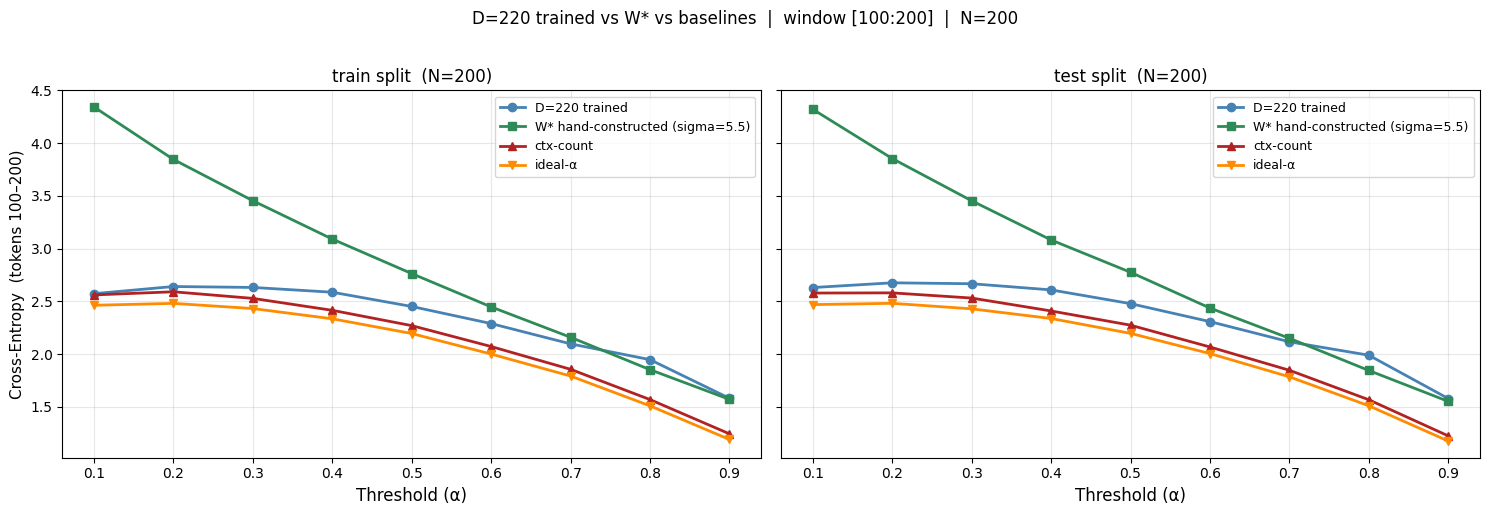

In [14]:
# ── Comparison plot: train vs test side-by-side ───────────────────────────────
# Left panel = train split, right panel = test split.  Same four curves each.
# (No dropdown — both splits are drawn together, so no duplicate render.)
# ──────────────────────────────────────────────────────────────────────────────

def plot_comparison_both(save=True):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for ax, split in zip(axes, ('train', 'test')):
        res  = results[split]
        thrs = sorted(res.keys())
        gd_ce   = [res[t]['gd']   for t in thrs]
        ws_ce   = [res[t]['ws']   for t in thrs]
        alp_ce  = [res[t]['alp']  for t in thrs]
        ialp_ce = [res[t]['ialp'] for t in thrs]

        ax.plot(thrs, gd_ce,   'o-', color='steelblue',  linewidth=2, label='D=220 trained')
        ax.plot(thrs, ws_ce,   's-', color='seagreen',   linewidth=2,
                label=f'W* hand-constructed (sigma={WS_SIGMA})')
        ax.plot(thrs, alp_ce,  '^-', color='firebrick',  linewidth=2, label='ctx-count')
        ax.plot(thrs, ialp_ce, 'v-', color='darkorange', linewidth=2, label='ideal-α')

        ax.set_xlabel('Threshold (α)', fontsize=12)
        ax.set_title(f'{split} split  (N={N_SEQS})', fontsize=12)
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel(f'Cross-Entropy  (tokens {TOKEN_START}–{TOKEN_END})', fontsize=11)
    fig.suptitle(
        f'D=220 trained vs W* vs baselines  |  window [{TOKEN_START}:{TOKEN_END}]  |  N={N_SEQS}',
        fontsize=12, y=1.02
    )
    plt.tight_layout()
    if save:
        out_path = os.path.join(MODELS_DIR, 'ce_comparison_train_test.png')
        plt.savefig(out_path, dpi=150, bbox_inches='tight')
        print(f'Saved → {out_path}')
    plt.show()

plot_comparison_both()


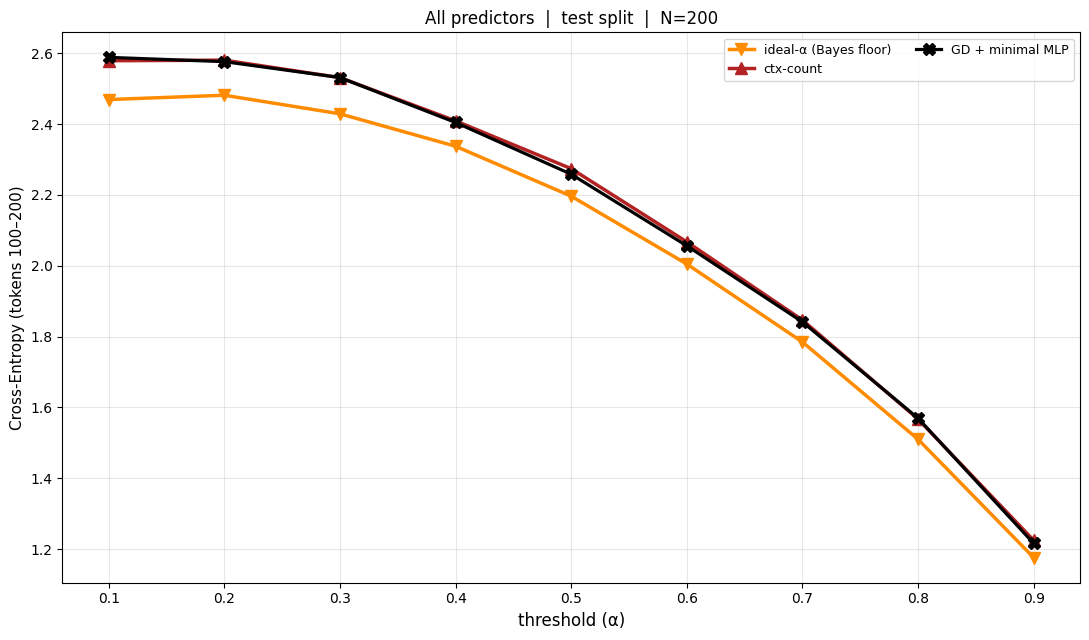

Saved → models/ce_all_test.png
α        ideal-α  ctx-count         GD
0.1       2.4693     2.5789     2.5884
0.2       2.4815     2.5805     2.5763
0.3       2.4290     2.5313     2.5314
0.4       2.3374     2.4090     2.4045
0.5       2.1964     2.2741     2.2584
0.6       2.0048     2.0673     2.0562
0.7       1.7845     1.8465     1.8413
0.8       1.5097     1.5668     1.5692
0.9       1.1756     1.2243     1.2157


In [11]:
# ══ ALL-IN-ONE CE comparison (single plot) ════════════════════════════════════
# Self-contained: depends ONLY on the SETTINGS cell (results, thresholds, classes,
# load_data, device, ...).  Safe to delete the 3 separate plot cells
# (W*-better / L1-head / freeze-readout) — this also re-exports SPLIT/better_par/
# WBETTER_PAR so the downstream KL & split-by-target cells keep working.
# ── EDIT HERE ─────────────────────────────────────────────────────────────────

SPLIT      = 'test'                                          # 'test' or 'train'
SIG_LIST   = [3.0, 3.0, 4.0, 4.5, 5.0, 5.0, 6.0, 6.0, 6.0]   # W*-better σ per α
BN_LIST    = [3.0, 2.0, 2.0, 1.5, 1.5, 1.0, 1.0, 0.5, -0.5]  # W*-better noise-bias per α
L1_PAR     = {0.1:(1e-2,3e-1), 0.2:(1e-2,3e-1), 0.3:(1e-2,3e-1),   # L1-head floor (b_sig,
              0.4:(3e-3,1e-1), 0.5:(3e-3,1e-1), 0.6:(3e-3,1e-1),   # b_noise) per α —
              0.7:(1e-3,3e-2), 0.8:(1e-3,3e-2), 0.9:(1e-3,1e-2)}   # grid-optimal, no search
FREEZE_TAG = 'freeze_readout'                                # freeze-model file tag
FREEZE_EPS = 1e-6
MLP_TAG    = 'mlp'                                           # MLP-model tag (train_with_mlp.py)
SHOW = dict(ideal=True, ctx=True, gd=False, wstar=False,
            wbetter=False, l1=False, freeze=False, mlp=True)    # toggle any curve off
# ──────────────────────────────────────────────────────────────────────────────
import os, json as _json
import numpy as np, torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
_thrs = sorted(thresholds)
assert len(SIG_LIST) == len(BN_LIST) == len(_thrs), f'lists must be length {len(_thrs)}'
_par = {t: (float(SIG_LIST[i]), float(BN_LIST[i])) for i, t in enumerate(_thrs)}

# W* built once (weights identical across thresholds)
_x0, _y0, _sl0, _V0, _bl0 = load_data(SPLIT, _thrs[0])
_WSm = PerfectInductionTransformer(_V0, _sl0, int(_bl0['vocab_set1'])).to(device).eval()

@torch.no_grad()
def _wlogits(blob):
    return _WSm(blob['x'].to(device))[:, TOKEN_START:TOKEN_END].cpu()

def _ce_logits(L, y):                       # softmax CE from raw logits
    return F.cross_entropy(L.reshape(-1, L.shape[-1]), y.reshape(-1)).item()

def _l1_ce(L, yw, V, Vs, bsig, bnoise):     # (freq+b)/Σ with the given per-class floor
    f = L.clamp_min(0.0)
    b = torch.zeros(V); b[:Vs] = bsig; b[Vs:] = bnoise
    p = f + b; p = p / p.sum(-1, keepdim=True)
    fl = p.reshape(-1, V).clamp_min(1e-12)
    return (-torch.log(fl[torch.arange(fl.shape[0]), yw.reshape(-1)])).mean().item()

def _freeze_ce(thr, seq_len, V):            # divide-by-sum CE of the trained freeze model
    mp = os.path.join(MODELS_DIR, f'model_{FREEZE_TAG}_x_{thr}.pth')
    if not os.path.exists(mp): return None
    cfgp = os.path.join(MODELS_DIR, f'metrics_{FREEZE_TAG}_x_{thr}.json')
    ad = ATTN_DIM
    if os.path.exists(cfgp):
        ad = int(_json.load(open(cfgp)).get('config', {}).get('attn_dim', ATTN_DIM))
    m = DisentangledTransformer(V, seq_len, ad, bias=True).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    x, y, _, _, _ = load_data(SPLIT, thr)
    with torch.no_grad():
        out = m(x.to(device))[:, TOKEN_START:TOKEN_END]
        p = (out + FREEZE_EPS) / (out.sum(-1, keepdim=True) + V * FREEZE_EPS)
        yw = y[:, TOKEN_START:TOKEN_END].to(device)
        ce = F.nll_loss(torch.log(p).reshape(-1, V), yw.reshape(-1)).item()
    del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

# minimal-MLP model (matches train_with_mlp.py); standard softmax CE
class _DTMLP(nn.Module):
    def __init__(self, V, T, ad, mh, bias=True, act='gelu'):
        super().__init__()
        self.total_vocab=V; self.seq_len=T; self.attn_dim=ad; self.initial_dim=V+T
        self.layer1=ConcatAttentionBlock(self.initial_dim, ad)
        self.layer2=ConcatAttentionBlock(self.initial_dim+ad, ad)
        D=self.initial_dim+2*ad
        self.ff1=nn.Linear(D, mh); self.ff2=nn.Linear(mh, D)
        self.act=nn.GELU() if act=='gelu' else nn.ReLU()
        self.fc_out=nn.Linear(D, V, bias=bias)
    def forward(self, x):
        B,T=x.shape
        tok=F.one_hot(x, self.total_vocab).float()
        pos=F.one_hot(torch.arange(T, device=x.device), self.seq_len).float().unsqueeze(0).expand(B,T,-1)
        s=torch.cat([tok,pos],-1)
        mm=torch.triu(torch.ones(T,T,device=x.device)*float('-inf'),1)
        s,_=self.layer1(s,mm); s,_=self.layer2(s,mm)
        s=s+self.ff2(self.act(self.ff1(s)))
        return self.fc_out(s)

def _mlp_ce(thr, seq_len, V):               # standard softmax CE of the trained MLP model
    mp = os.path.join(MODELS_DIR, f'model_{MLP_TAG}_x_{thr}.pth')
    if not os.path.exists(mp): return None
    cfgp = os.path.join(MODELS_DIR, f'metrics_{MLP_TAG}_x_{thr}.json'); ad=ATTN_DIM; mh=128; act='gelu'
    if os.path.exists(cfgp):
        cfg=_json.load(open(cfgp)).get('config', {}); ad=int(cfg.get('attn_dim',ATTN_DIM)); mh=int(cfg.get('mlp_hidden',128)); act=cfg.get('mlp_act','gelu')
    m = _DTMLP(V, seq_len, ad, mh, bias=True, act=act).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    x, y, _, _, _ = load_data(SPLIT, thr)
    ce = compute_ce(m, x, y, V)             # SETTINGS helper: softmax CE on the window
    del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

# ── collect every curve ───────────────────────────────────────────────────────
res = results[SPLIT]
CURVES = {k: [] for k in ('gd', 'ctx', 'ideal', 'wstar', 'wbetter', 'l1', 'freeze', 'mlp')}
for t in _thrs:
    x, y, seq_len, V, blob = load_data(SPLIT, t)
    yw = y[:, TOKEN_START:TOKEN_END]; Vs = int(blob['vocab_set1'])
    CURVES['gd'].append(res[t]['gd']); CURVES['ctx'].append(res[t]['alp'])
    CURVES['ideal'].append(res[t]['ialp']); CURVES['wstar'].append(res[t]['ws'])
    L = _wlogits(blob)
    nmask = torch.zeros(V); nmask[Vs:] = 1.0
    sig, bn = _par[t]
    CURVES['wbetter'].append(_ce_logits(L * sig + nmask * bn, yw))
    _bs, _bn = L1_PAR.get(round(t, 1), (1e-3, 1e-1))
    CURVES['l1'].append(_l1_ce(L, yw, V, Vs, _bs, _bn))
    CURVES['freeze'].append(_freeze_ce(t, seq_len, V))
    CURVES['mlp'].append(_mlp_ce(t, seq_len, V))

# ── one plot ──────────────────────────────────────────────────────────────────
SPECS = [('ideal',   'ideal-α (Bayes floor)',     'v-', 'darkorange', 2.5, 8),
         ('ctx',     'ctx-count',                 '^-', 'firebrick',  2.5, 8),
         ('gd',      'GD trained (softmax)',      'o-', 'steelblue',  2.0, 8),
         ('wstar',   f'W* hand (σ={WS_SIGMA})',   's-', 'seagreen',   2.0, 8),
         ('wbetter', 'W*-better (per-α σ,bN)',    'D-', 'purple',     2.3, 8),
         ('l1',      'L1 head (freq, best-fit b)','P-', 'crimson',    2.0, 8),
         ('freeze',  'GD freeze-readout (+bias)', '*-', 'magenta',    2.3, 13),
         ('mlp',     'GD + minimal MLP',          'X-', 'black',      2.3, 9)]
fig, ax = plt.subplots(figsize=(11, 6.5))
for key, label, style, color, lw, ms in SPECS:
    if not SHOW.get(key): continue
    ys = CURVES[key]
    xs = [t for t, v in zip(_thrs, ys) if v is not None]
    yv = [v for v in ys if v is not None]
    if not yv: continue
    ax.plot(xs, yv, style, color=color, lw=lw, ms=ms, label=label)
ax.set_xlabel('threshold (α)', fontsize=12)
ax.set_ylabel(f'Cross-Entropy (tokens {TOKEN_START}–{TOKEN_END})', fontsize=11)
ax.set_title(f'All predictors  |  {SPLIT} split  |  N={N_SEQS}', fontsize=12)
ax.legend(fontsize=9, ncol=2); ax.grid(True, alpha=0.3); plt.tight_layout()
_out = os.path.join(MODELS_DIR, f'ce_all_{SPLIT}.png'); plt.savefig(_out, dpi=150)
plt.show(); print('Saved →', _out)

# ── numeric table ─────────────────────────────────────────────────────────────
cols = [s for s in SPECS if SHOW.get(s[0])]
print('α    ' + ''.join(f'{lbl.split()[0]:>11}' for _, lbl, *_ in cols))
for i, t in enumerate(_thrs):
    vals = ''.join(f'{(CURVES[k][i] if CURVES[k][i] is not None else float("nan")):>11.4f}'
                   for k, *_ in cols)
    print(f'{t:<5}{vals}')

# keep downstream cells (KL / split-by-target) working after deleting old cells:
WBETTER_PAR = dict(_par); better_par = dict(_par)


Sequence 0 | test | α=0.7 | positions [150,200) | T=200
Markov chain (this sequence):
   0 -> {5, 4}
   1 -> {7, 2}
   2 -> {1, 3}
   3 -> {3, 0}
   4 -> {6, 9}
   5 -> {3, 8}
   6 -> {2, 0}
   7 -> {7, 4}
   8 -> {2, 8}
   9 -> {2, 7}

Table shows 'mlp' argmax.  pos | x[t] | y[t] | pred | ok | p(y[t]) | governing-state -> {succ}
   pos    x    y pred  ok     p(y)  state->succ
   150    6   12    0   .   0.0373  6->{2,0}
   151   12    2    2   Y   0.3573  6->{2,0}
   152    2    1    1   Y   0.3722  2->{1,3}
   153    1    2    2   Y   0.3998  1->{7,2}
   154    2    3    1   .   0.2837  2->{1,3}
   155    3    0    0   Y   0.4327  3->{3,0}
   156    0    4    4   Y   0.3680  0->{5,4}
   157    4    9    6   .   0.3398  4->{6,9}
   158    9   11    2   .   0.0250  9->{2,7}
   159   11    2    2   Y   0.3124  9->{2,7}
   160    2   17    1   .   0.0374  2->{1,3}
   161   17    1    1   Y   0.3762  2->{1,3}
   162    1    2    2   Y   0.3912  1->{7,2}
   163    2    3    1   .   0.3041 

/tmp/ipykernel_1851015/3508828779.py:214: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


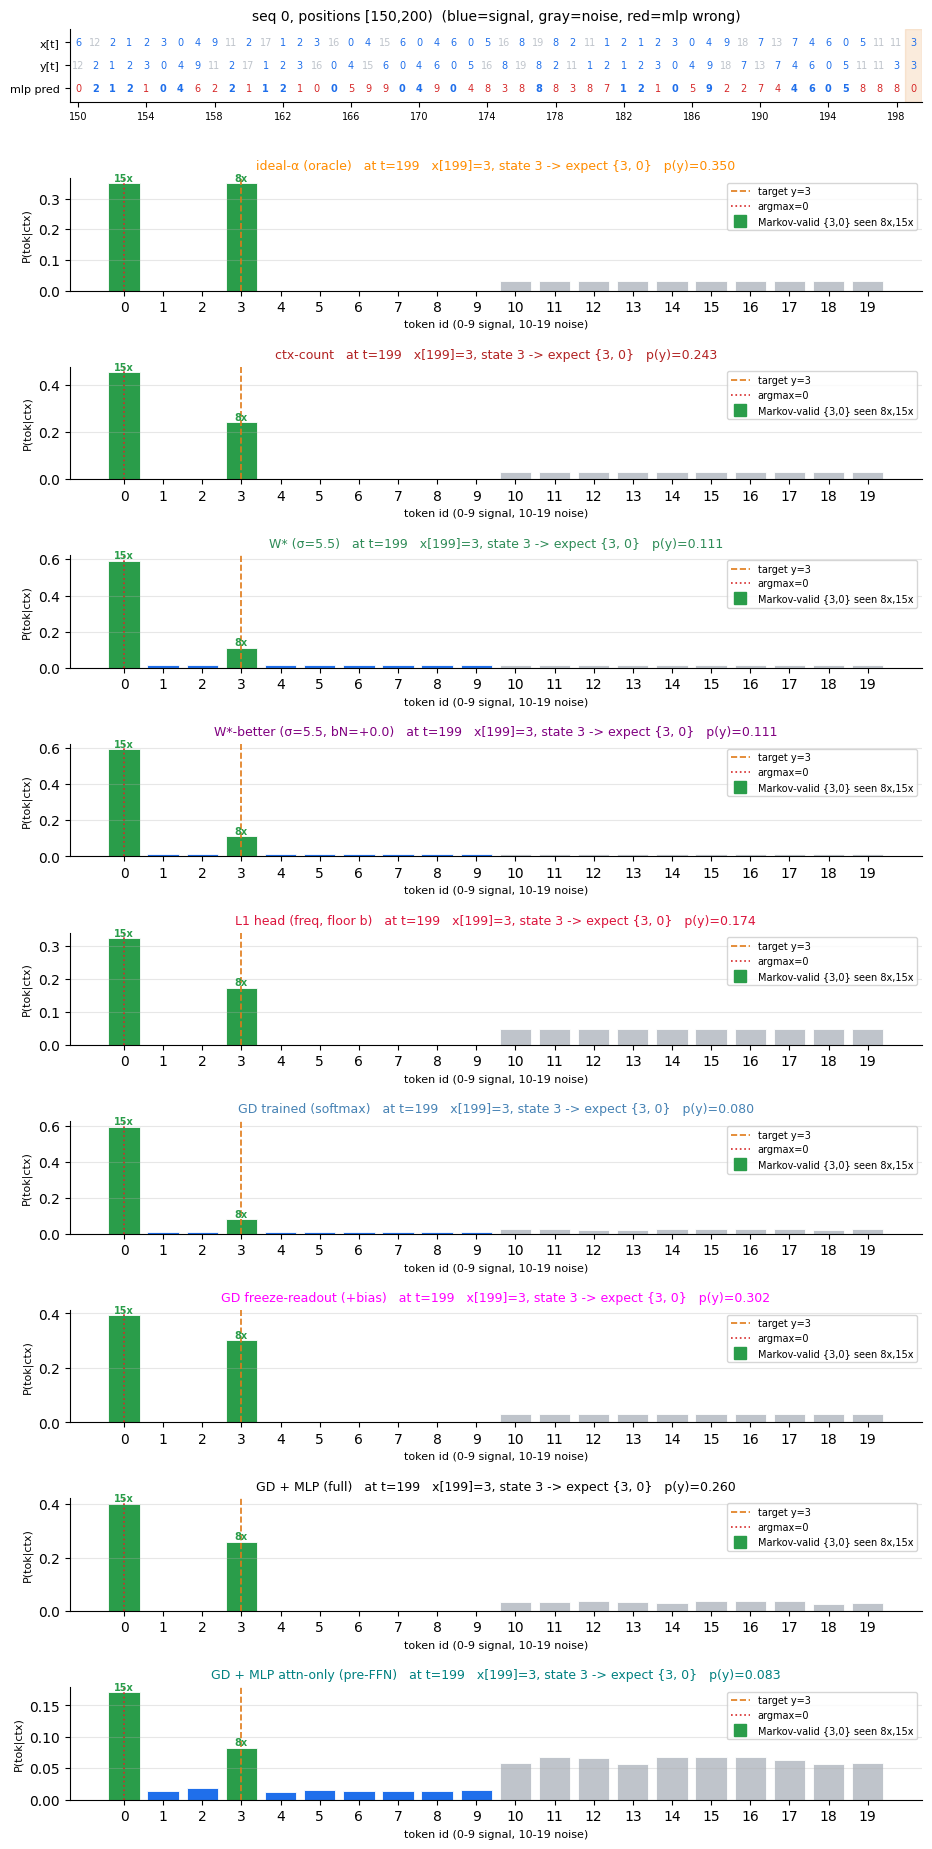


Saved -> models/inspect_all_seq0_thr0.7_fp199.png


In [3]:

# ══ PER-POSITION PROBABILITY DIAGNOSTIC — every predictor at one focus token ════
# Token strip + ground-truth Markov chain + a P(token|context) bar chart for EACH
# predictor at FOCUS_POS:  ideal-α, ctx-count, W*, W*-better, L1-head, GD-softmax,
# GD freeze-readout(+bias), GD+MLP.  Self-contained (uses SETTINGS-cell objects).

# ── EDIT HERE ─────────────────────────────────────────────────────────────────
INSPECT_THRESH = 0.7
INSPECT_SPLIT  = 'test'        # 'test' or 'train'
SEQ_IDX        = 0             # which sequence in the split
RANGE_START    = 150           # first printed position (None → T-50)
RANGE_END      = 200           # last printed position, exclusive (None → T)
FOCUS_POS      = 199           # position for the bar charts (None → RANGE_END-1)
INSPECT_SIGMA  = WS_SIGMA      # W* temperature for the plain-W* bar
FREEZE_EPS_I   = 1e-6
STRIP_MODEL    = 'mlp'         # whose argmax is shown in the token strip/table
SHOW_INSPECT   = dict(ideal=True, ctx=True, wstar=True, wbetter=True, l1=True,
                      gd=True, freeze=True, mlp=True, mlp_pre=True)
# ──────────────────────────────────────────────────────────────────────────────
import os, json as _json
import numpy as np, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

class _DTMLP(nn.Module):                        # matches train_with_mlp.py
    def __init__(self, V, T, ad, mh, bias=True, act='gelu'):
        super().__init__()
        self.total_vocab=V; self.seq_len=T; self.attn_dim=ad; self.initial_dim=V+T
        self.layer1=ConcatAttentionBlock(self.initial_dim, ad)
        self.layer2=ConcatAttentionBlock(self.initial_dim+ad, ad)
        D=self.initial_dim+2*ad
        self.ff1=nn.Linear(D, mh); self.ff2=nn.Linear(mh, D)
        self.act=nn.GELU() if act=='gelu' else nn.ReLU()
        self.fc_out=nn.Linear(D, V, bias=bias)
    def _attn(self, x):
        B,T=x.shape
        tok=F.one_hot(x, self.total_vocab).float()
        pos=F.one_hot(torch.arange(T, device=x.device), self.seq_len).float().unsqueeze(0).expand(B,T,-1)
        s2=torch.cat([tok,pos],-1)
        mm=torch.triu(torch.ones(T,T,device=x.device)*float('-inf'),1)
        s2,_=self.layer1(s2,mm); s2,_=self.layer2(s2,mm)
        return s2
    def forward(self, x):
        s2=self._attn(x)
        s2=s2+self.ff2(self.act(self.ff1(s2)))
        return self.fc_out(s2)
    def forward_both(self, x):                      # (pre-FFN readout, full readout)
        s2=self._attn(x)
        pre=self.fc_out(s2)
        full=self.fc_out(s2+self.ff2(self.act(self.ff1(s2))))
        return pre, full

def _inspect():
    thr = INSPECT_THRESH
    xs, ys, T, V, bl = load_data(INSPECT_SPLIT, thr, n_cap=max(N_SEQS, SEQ_IDX+1))
    V_sig = int(bl['vocab_set1'])
    assert 0 <= SEQ_IDX < xs.shape[0], f'SEQ_IDX out of range (have {xs.shape[0]})'
    x_seq = xs[SEQ_IDX]; y_seq = ys[SEQ_IDX]; ta = bl['transitions'][SEQ_IDX]
    x_np = x_seq.numpy(); y_np = y_seq.numpy()
    xb = x_seq.unsqueeze(0).to(device)

    rs = max(0, T-50) if RANGE_START is None else max(0, int(RANGE_START))
    re = T if RANGE_END is None else min(T, int(RANGE_END))
    fp = (re-1) if FOCUS_POS is None else int(FOCUS_POS)
    assert 0 <= rs < re <= T and 0 <= fp < T

    # last-ruled (governing state) at every position
    lr_arr = np.full(T, -1); cur=-1
    for t in range(T):
        if x_np[t] < V_sig: cur=int(x_np[t])
        lr_arr[t]=cur

    # ── W* (built once) → frequency logits ──────────────────────────────────
    wstar = PerfectInductionTransformer(V, T, V_sig).to(device).eval()
    with torch.no_grad(): ws_logits = wstar(xb)[0]                 # [T,V], =freq vec (>=0)
    ws_p = F.softmax(ws_logits*INSPECT_SIGMA, -1).cpu().numpy()

    nmask = torch.zeros(V, device=device); nmask[V_sig:]=1.0
    sig_wb, bn_wb = (WBETTER_PAR.get(round(thr,1),(INSPECT_SIGMA,0.0))
                     if 'WBETTER_PAR' in globals() else (INSPECT_SIGMA,0.0))
    wb_p = F.softmax(ws_logits*float(sig_wb)+nmask*float(bn_wb), -1).cpu().numpy()

    bs_l1, bn_l1 = (L1_PAR.get(round(thr,1),(1e-3,1e-1)) if 'L1_PAR' in globals() else (1e-3,1e-1))
    bvec = torch.zeros(V, device=device); bvec[:V_sig]=bs_l1; bvec[V_sig:]=bn_l1
    l1f = ws_logits.clamp_min(0.0)+bvec; l1_p = (l1f/l1f.sum(-1,keepdim=True)).cpu().numpy()

    # ── trained models (load attn_dim from each metrics file) ───────────────
    def _meta(tag):
        f = (f'metrics_x_{thr}.json' if tag=='' else f'metrics_{tag}_x_{thr}.json')
        p = os.path.join(MODELS_DIR, f)
        return _json.load(open(p)).get('config',{}) if os.path.exists(p) else {}
    def _load(tag, mlp=False):
        fn = (f'model_x_{thr}.pth' if tag=='' else f'model_{tag}_x_{thr}.pth')
        mp = os.path.join(MODELS_DIR, fn)
        if not os.path.exists(mp): return None
        c=_meta(tag); ad=int(c.get('attn_dim',ATTN_DIM))
        if mlp: m=_DTMLP(V,T,ad,int(c.get('mlp_hidden',128)),bias=True,act=c.get('mlp_act','gelu')).to(device)
        else:   m=DisentangledTransformer(V,T,ad,bias=True).to(device)
        m.load_state_dict(torch.load(mp,map_location=device,weights_only=True)); m.eval(); return m

    gd_p=fr_p=ml_p=ml_pre_p=None
    m=_load('')
    if m is not None:
        with torch.no_grad(): gd_p=F.softmax(m(xb)[0],-1).cpu().numpy()
        del m
    m=_load('freeze_readout')
    if m is not None:
        with torch.no_grad(): o=m(xb)[0]; fr_p=((o+FREEZE_EPS_I)/(o.sum(-1,keepdim=True)+V*FREEZE_EPS_I)).cpu().numpy()
        del m
    m=_load('mlp', mlp=True)
    if m is not None:
        with torch.no_grad():
            _pre,_full=m.forward_both(xb)
            ml_p=F.softmax(_full[0],-1).cpu().numpy()          # full (attn + FFN)
            ml_pre_p=F.softmax(_pre[0],-1).cpu().numpy()       # attn only, FFN ablated
        del m
    if device.type=='cuda': torch.cuda.empty_cache()

    # ── ctx-count and ideal-α full [T,V] ────────────────────────────────────
    ctx_p=np.zeros((T,V)); tc=np.zeros((V,V_sig)); pend=np.zeros(V); lr=-1; eps=0.01
    ideal_p=np.zeros((T,V))
    for t in range(T):
        xt=int(x_np[t])
        if xt<V_sig: tc[:,xt]+=pend; pend[:]=0; pend[xt]=1; lr=xt
        else:        pend[xt]+=1
        q = xt if xt<V_sig else max(lr,0)
        cs=tc[q]+eps; ts=cs.sum()
        p=np.zeros(V); p[:V_sig]=cs/ts*thr; p[V_sig:]=(1-thr)/(V-V_sig); ctx_p[t]=p
        st=lr_arr[t]; pi=np.zeros(V); pi[V_sig:]=(1-thr)/(V-V_sig)
        if st>=0: pi[int(ta[st][0])]+=thr/2; pi[int(ta[st][1])]+=thr/2
        else:     pi[:V_sig]+=thr/V_sig
        ideal_p[t]=pi

    # ── assemble predictor panels ───────────────────────────────────────────
    ALL=[('ideal','ideal-α (oracle)',ideal_p,'darkorange'),
         ('ctx','ctx-count',ctx_p,'firebrick'),
         ('wstar',f'W* (σ={INSPECT_SIGMA})',ws_p,'seagreen'),
         ('wbetter',f'W*-better (σ={sig_wb:.1f}, bN={bn_wb:+.1f})',wb_p,'purple'),
         ('l1','L1 head (freq, floor b)',l1_p,'crimson')]
    if gd_p is not None: ALL.append(('gd','GD trained (softmax)',gd_p,'steelblue'))
    if fr_p is not None: ALL.append(('freeze','GD freeze-readout (+bias)',fr_p,'magenta'))
    if ml_p is not None: ALL.append(('mlp','GD + MLP (full)',ml_p,'black'))
    if ml_pre_p is not None: ALL.append(('mlp_pre','GD + MLP attn-only (pre-FFN)',ml_pre_p,'teal'))
    PRED=[p for p in ALL if SHOW_INSPECT.get(p[0],True)]
    PMAP={k:(lbl,arr,col) for k,lbl,arr,col in PRED}

    state_fp=int(lr_arr[fp])
    exp = (int(ta[state_fp][0]),int(ta[state_fp][1])) if state_fp>=0 else None
    # context evidence: how many times the governing state was followed by each token (induction count)
    ctx_cnt=np.zeros(V,int)
    for _t in range(fp):
        if lr_arr[_t]==state_fp: ctx_cnt[int(y_np[_t])]+=1
    raw_cnt=np.array([int((x_np[:fp]==k).sum()) for k in range(V)])

    # ── printout: Markov chain + table ──────────────────────────────────────
    print(f"Sequence {SEQ_IDX} | {INSPECT_SPLIT} | α={thr} | positions [{rs},{re}) | T={T}")
    print("Markov chain (this sequence):")
    for r in range(V_sig):
        print(f"   {r} -> {{{int(ta[r][0])}, {int(ta[r][1])}}}")
    strip_key = STRIP_MODEL if STRIP_MODEL in PMAP else PRED[-1][0]
    strip_arr = PMAP[strip_key][1]; strip_pred = strip_arr.argmax(-1)
    print(f"\nTable shows '{strip_key}' argmax.  pos | x[t] | y[t] | pred | ok | p(y[t]) | governing-state -> {{succ}}")
    print(f"  {'pos':>4} {'x':>4} {'y':>4} {'pred':>4} {'ok':>3} {'p(y)':>8}  state->succ")
    for t in range(rs, re):
        ok='Y' if strip_pred[t]==y_np[t] else '.'
        st=int(lr_arr[t]); succ=f"{st}->{{{int(ta[st][0])},{int(ta[st][1])}}}" if st>=0 else "(none)"
        mk=' <-FP' if t==fp else ''
        print(f"  {t:>4} {int(x_np[t]):>4} {int(y_np[t]):>4} {int(strip_pred[t]):>4} {ok:>3} {strip_arr[t,y_np[t]]:8.4f}  {succ}{mk}")
    nc=int((strip_pred[rs:re]==y_np[rs:re]).sum())
    print(f"\n  '{strip_key}' acc on range: {nc}/{re-rs} = {nc/(re-rs):.1%}")
    print(f"  x[{fp}]={int(x_np[fp])}  governing state={state_fp}  Markov-valid next={exp}  target y[{fp}]={int(y_np[fp])}")
    if exp:
        print(f"  context evidence (state {state_fp}->next): succ {exp[0]}={ctx_cnt[exp[0]]}x, "
              f"succ {exp[1]}={ctx_cnt[exp[1]]}x, noise={int(ctx_cnt[V_sig:].sum())}x   |   "
              f"raw token appearances in ctx: {exp[0]}={raw_cnt[exp[0]]}, {exp[1]}={raw_cnt[exp[1]]}")

    # ── figure: strip + one bar per predictor ───────────────────────────────
    BLUE='#1f6feb'; ORANGE='#e07a18'; GRAY='#bfc4cb'; RED='#d62828'; GREEN='#2a9d4a'
    n=len(PRED); cols=re-rs
    fig=plt.figure(figsize=(max(11,cols*0.22), 3.2+2.2*n))
    gs=fig.add_gridspec(1+n,1,height_ratios=[1.3]+[2.0]*n, hspace=0.7)
    ax=fig.add_subplot(gs[0])
    for j,t in enumerate(range(rs,re)):
        ax.text(j,2,str(int(x_np[t])),ha='center',va='center',fontsize=7,color=(BLUE if x_np[t]<V_sig else GRAY))
        ax.text(j,1,str(int(y_np[t])),ha='center',va='center',fontsize=7,color=(BLUE if y_np[t]<V_sig else GRAY))
        ax.text(j,0,str(int(strip_pred[t])),ha='center',va='center',fontsize=7,
                color=(BLUE if strip_pred[t]==y_np[t] else RED),
                fontweight=('bold' if strip_pred[t]==y_np[t] else 'normal'))
    if rs<=fp<re: ax.axvspan(fp-rs-0.5,fp-rs+0.5,color=ORANGE,alpha=0.15,zorder=0)
    ax.set_yticks([0,1,2]); ax.set_yticklabels([f'{strip_key} pred','y[t]','x[t]'],fontsize=8)
    ax.set_xticks(range(0,cols,max(1,cols//12))); ax.set_xticklabels([str(rs+i) for i in range(0,cols,max(1,cols//12))],fontsize=7)
    ax.set_xlim(-0.5,cols-0.5); ax.set_ylim(-0.6,2.6)
    ax.set_title(f"seq {SEQ_IDX}, positions [{rs},{re})  (blue=signal, gray=noise, red={strip_key} wrong)",fontsize=10)
    for sp in ['top','right']: ax.spines[sp].set_visible(False)

    chain = f"x[{fp}]={int(x_np[fp])}, state {state_fp} -> expect {{{exp[0]}, {exp[1]}}}" if exp else f"x[{fp}]={int(x_np[fp])} (no state)"
    for r,(key,lbl,arr,col) in enumerate(PRED):
        axb=fig.add_subplot(gs[1+r]); p1=arr[fp]
        bc=[BLUE if k<V_sig else GRAY for k in range(V)]
        if exp:
            for k in exp: bc[k]=GREEN
        axb.bar(range(V),p1,color=bc,edgecolor='white',linewidth=0.6)
        if exp:
            for k in exp:
                axb.text(k, p1[k], f"{int(ctx_cnt[k])}x", ha='center', va='bottom',
                         fontsize=7, color=GREEN, fontweight='bold')
        axb.axvline(int(y_np[fp]),color=ORANGE,lw=1.2,ls='--',label=f'target y={int(y_np[fp])}')
        axb.axvline(int(arr[fp].argmax()),color=RED,lw=1.2,ls=':',label=f'argmax={int(arr[fp].argmax())}')
        if exp: axb.plot([],[],'s',color=GREEN,markersize=8,label=f'Markov-valid {{{exp[0]},{exp[1]}}} seen {ctx_cnt[exp[0]]}x,{ctx_cnt[exp[1]]}x')
        axb.set_xticks(range(V)); axb.set_ylabel('P(tok|ctx)',fontsize=8)
        axb.set_xlabel('token id (0-9 signal, 10-19 noise)',fontsize=8)
        axb.legend(fontsize=7,loc='upper right'); axb.grid(axis='y',alpha=0.3)
        axb.set_title(f"{lbl}   at t={fp}   {chain}   p(y)={p1[int(y_np[fp])]:.3f}",fontsize=9,color=col)
        for sp in ['top','right']: axb.spines[sp].set_visible(False)
    plt.tight_layout()
    out=os.path.join(MODELS_DIR, f"inspect_all_seq{SEQ_IDX}_thr{thr}_fp{fp}.png")
    plt.savefig(out,dpi=150); plt.show(); print(f"\nSaved -> {out}")

_inspect()


THR=0.8   V=20  V_sig=10   W*-better σ=5.5

gauge-aware cosine(GD, W*-better):
  M_QK  layer 1              +0.123
  M_QK  layer 2              +0.163
  M_OV  layer 1              +0.004   [layer-1 OV rotation gauge NOT quotiented -> low cos OK]
  M_OV · Unembed  layer 2    +0.286


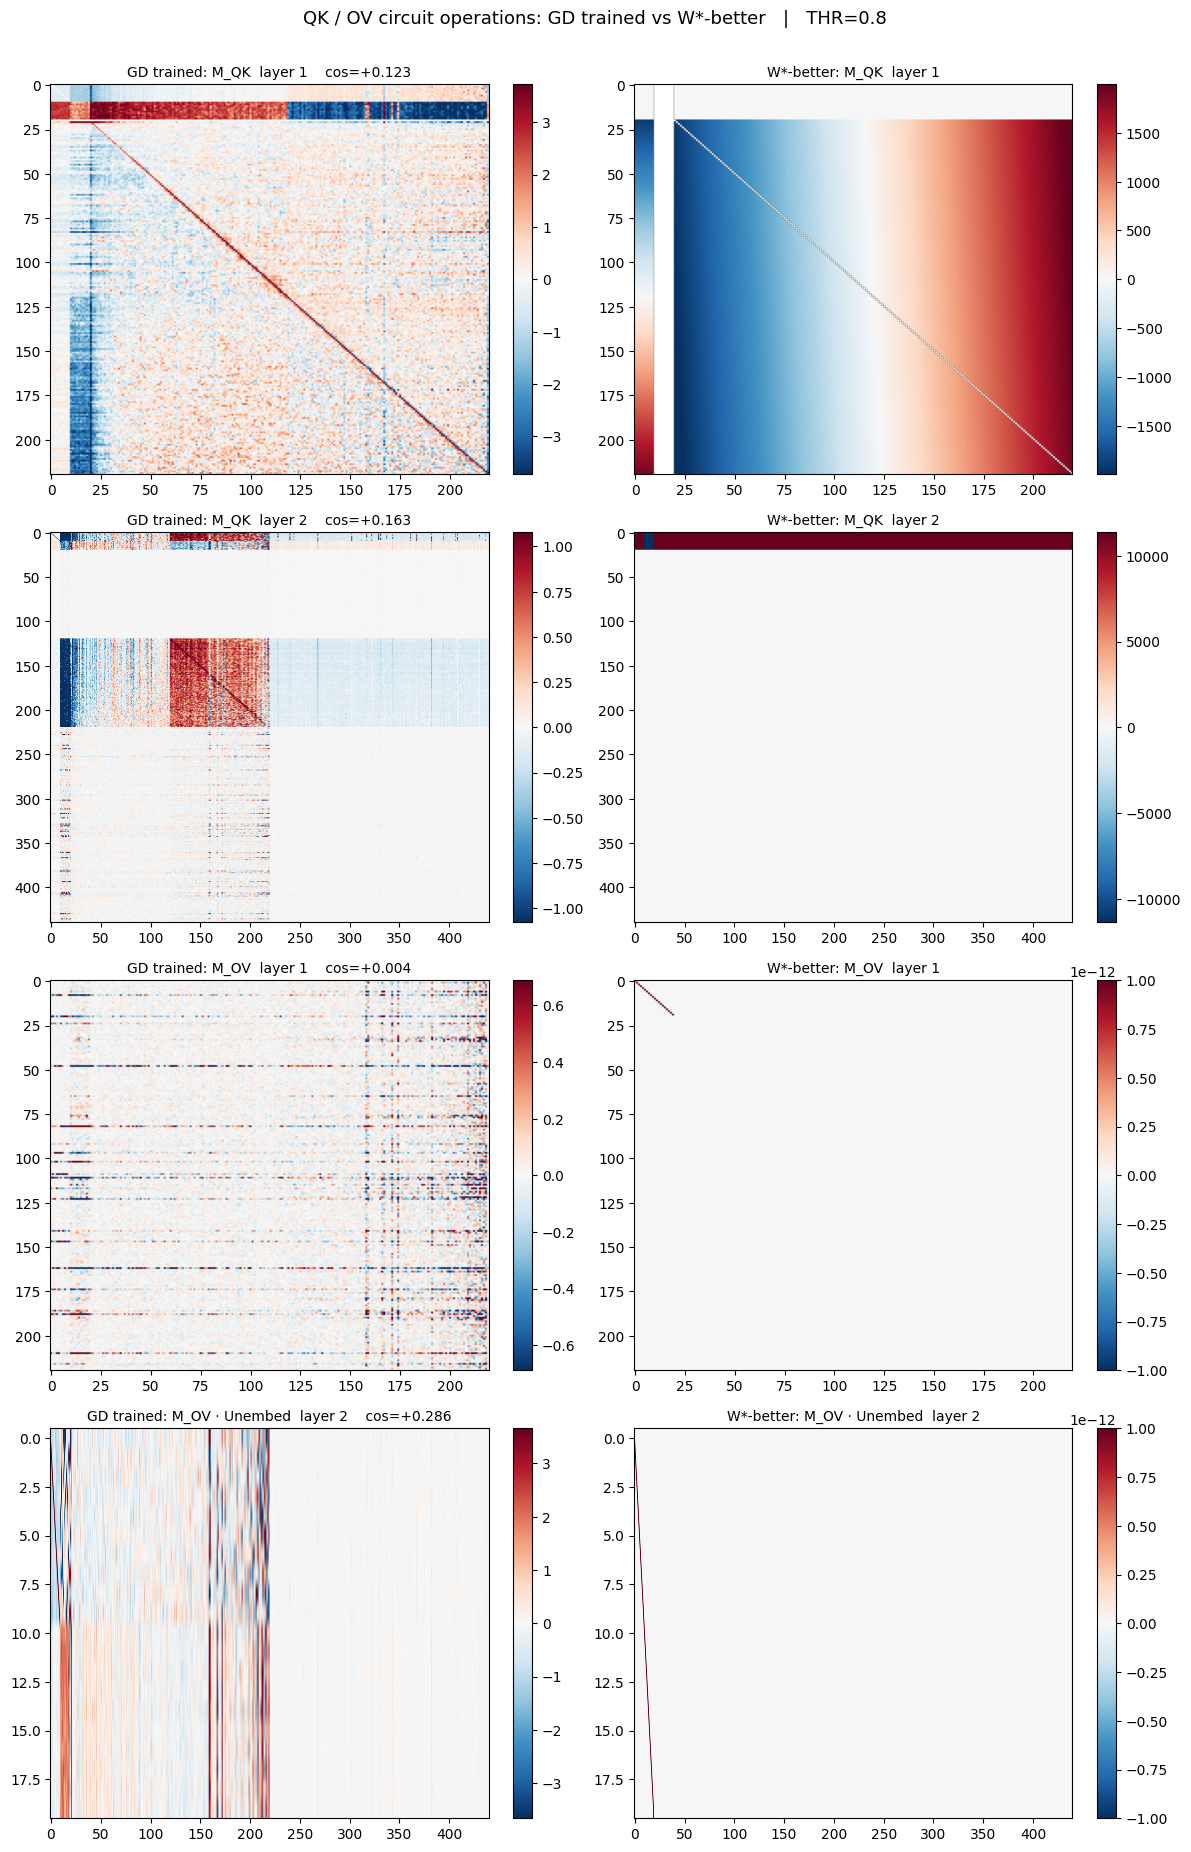

In [2]:
# ══ QK / OV CIRCUIT COMPARISON — GD trained  vs  W*-better, side by side ══════════
# For a chosen threshold, lay the gauge-relevant weight PRODUCTS side by side to ask:
# is GD learning the SAME circuit operations as the hand construction?
#   M_QK = Wqᵀ Wk / √d     QK circuit  (invariant to the Wq<->Wk rotation; a softmax
#                                       per-row additive gauge remains -> we row-demean)
#   M_OV = Wo  Wv          OV circuit  (layer-1 still carries a residual value-basis
#                                       rotation A A⁻¹ that is NOT cancelled here)
#   layer-2 OV is COMBINED with the unembedding:  fc_out_block · M_OV   so the A A⁻¹
#                          value-basis gauge cancels -> a gauge-invariant value→logit map.
# Two models = the ones used in the distribution cell:
#   'GD trained' = load_model(...)                  (separate Wq,Wk,Wv,Wo, learned)
#   'W*-better'  = PerfectInductionTransformer + per-α temperature σ on the readout
#                  (σ scales the layer-2 combined map; its noise-bias is additive, not shown).
# W* uses hard ±1e9 gates -> masked (|x|>1e6, white). Each panel has its OWN robust colour
# scale (magnitudes are not comparable across the gauge; the *pattern* is).
THR_M = 0.8     # <-- threshold to inspect (variable)

x_m, y_m, seq_len_m, V_m, blob_m = load_data('test', THR_M, n_cap=64)
V_sig_m = int(blob_m['vocab_set1'])
gd_m = load_model(THR_M, seq_len_m, V_m)
ws_m = PerfectInductionTransformer(V_m, seq_len_m, V_sig_m).to(device).eval()
try:    sig_wb = float(_par.get(THR_M, (WS_SIGMA, 0.0))[0])     # per-α σ from the all-in-one cell
except NameError:  sig_wb = WS_SIGMA
print(f'THR={THR_M}   V={V_m}  V_sig={V_sig_m}   W*-better σ={sig_wb}')

def circuits(model, sigma=1.0):
    l1, l2 = model.layer1, model.layer2
    d1 = l1.W_q.weight.shape[0]; d2 = l2.W_q.weight.shape[0]    # attention output dims
    Wqk1 = l1.W_q.weight.t() @ l1.W_k.weight / (d1 ** 0.5)
    Wqk2 = l2.W_q.weight.t() @ l2.W_k.weight / (d2 ** 0.5)
    Wov1 = l1.W_o.weight @ l1.W_v.weight                        # [d1, initial_dim]
    Wov2 = l2.W_o.weight @ l2.W_v.weight                        # [d2, D1]
    block2 = model.fc_out.weight[:, -Wov2.shape[0]:]           # fc_out cols reading attn_out2  [V, d2]
    comb2 = sigma * (block2 @ Wov2)                            # [V, D1]  value→logit (gauge-invariant)
    return {k: v.detach().cpu().numpy() for k, v in
            dict(Wqk1=Wqk1, Wqk2=Wqk2, Wov1=Wov1, comb2=comb2).items()}

C_gd = circuits(gd_m, 1.0)
C_wb = circuits(ws_m, sig_wb)

def _blank(M):  M = M.astype(float).copy(); M[np.abs(M) > 1e6] = np.nan; return M
def _rowdemean(M):  return M - np.nanmean(M, axis=1, keepdims=True)
def _prep(M, demean):  M = _blank(M); return _rowdemean(M) if demean else M
def _cos(A, B, demean):
    A, B = _prep(A, demean), _prep(B, demean)
    m = np.isfinite(A) & np.isfinite(B); a, b = A[m].ravel(), B[m].ravel()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

ROWS = [('M_QK  layer 1',           'Wqk1', True),
        ('M_QK  layer 2',           'Wqk2', True),
        ('M_OV  layer 1',           'Wov1', False),
        ('M_OV · Unembed  layer 2', 'comb2', False)]
fig, ax = plt.subplots(len(ROWS), 2, figsize=(12, 4.6 * len(ROWS)))
print('\ngauge-aware cosine(GD, W*-better):')
for r, (label, key, dem) in enumerate(ROWS):
    cos = _cos(C_gd[key], C_wb[key], dem)
    for col, (who, Cd) in enumerate([('GD trained', C_gd), ('W*-better', C_wb)]):
        M = _prep(Cd[key], dem); q = np.nanpercentile(np.abs(M), 99) + 1e-12
        im = ax[r, col].imshow(M, cmap='RdBu_r', vmin=-q, vmax=q, aspect='auto')
        ax[r, col].set_title(f'{who}: {label}' + (f'    cos={cos:+.3f}' if col == 0 else ''), fontsize=10)
        plt.colorbar(im, ax=ax[r, col], fraction=0.046)
    note = '   [layer-1 OV rotation gauge NOT quotiented -> low cos OK]' if key == 'Wov1' else ''
    print(f'  {label:26s} {cos:+.3f}{note}')
plt.suptitle(f'QK / OV circuit operations: GD trained vs W*-better   |   THR={THR_M}', y=1.004, fontsize=13)
plt.tight_layout(); plt.show()

## Comparing GD-learned weights with the hand-coded W\*

**Why we can't compare raw weights.** Each attention block has a *gauge freedom*: the scores depend on `(W_q, W_k)` only through `M_QK = W_qᵀ W_k`, and the value path depends on `(W_v, W_o)` only through `M_OV = W_o W_v`. Any invertible `R` with `W_q → R W_q`, `W_k → R⁻ᵀ W_k` leaves the computed function unchanged — so GD's `W_q` need not resemble the hand-coded one even when both networks compute the **same map**. Entry-wise weight comparison is therefore meaningless.

We instead compare **gauge-invariant** quantities, in the *fixed, interpretable* coordinates (input = token[0:20] ⊕ position[0:200]; output = vocab):

1. **Functional** — does GD's predictive distribution equal the count-α one? Per-threshold `KL(GD ‖ ctx-count)` vs `KL(GD ‖ W*)`.
2. **Behavioral** — does GD implement the induction circuit? Layer-1 = previous-position head; Layer-2 = attend to keys whose *previous* token equals the current token, then copy.
3. **Structural** — `M_QK⁽¹⁾` in token/position coordinates, and the signal-token **permutation symmetry** the task demands (a correct solution must be S₁₀-equivariant over the signal tokens).

> Run the evaluation cell above first — it defines `device`, `load_data`, `load_model`, `PerfectInductionTransformer`, `thresholds`, `TOKEN_START/END`, `WS_SIGMA`, `N_SEQS`.

In [8]:
# ── Setup: load one GD model + the hand-coded W* at the same threshold ────────
THR   = 0.9    # inspect a well-trained threshold in detail
N_CMP = 128     # sequences for the detailed (single-threshold) comparisons

x_c, y_c, seq_len, V, blob_c = load_data('test', THR, n_cap=N_CMP)
V_sig    = int(blob_c['vocab_set1'])
gd_model = load_model(THR, seq_len, V)
ws_model = PerfectInductionTransformer(V, seq_len, V_sig).to(device).eval()
print(f'THR={THR}  seq_len={seq_len}  V={V}  V_sig={V_sig}  N={x_c.shape[0]}')

THR=0.9  seq_len=200  V=20  V_sig=10  N=128


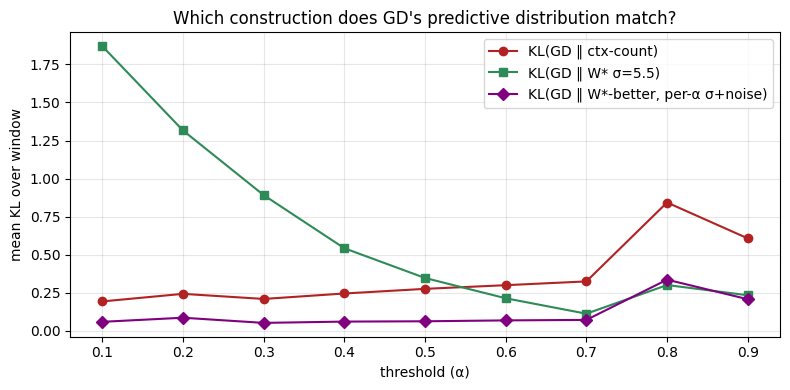

  α=0.1   KL→ctx=0.194   KL→W*=1.870   KL→W*-better=0.060
  α=0.2   KL→ctx=0.244   KL→W*=1.316   KL→W*-better=0.087
  α=0.3   KL→ctx=0.210   KL→W*=0.892   KL→W*-better=0.053
  α=0.4   KL→ctx=0.246   KL→W*=0.543   KL→W*-better=0.062
  α=0.5   KL→ctx=0.277   KL→W*=0.348   KL→W*-better=0.064
  α=0.6   KL→ctx=0.301   KL→W*=0.215   KL→W*-better=0.070
  α=0.7   KL→ctx=0.325   KL→W*=0.113   KL→W*-better=0.073
  α=0.8   KL→ctx=0.843   KL→W*=0.302   KL→W*-better=0.337
  α=0.9   KL→ctx=0.608   KL→W*=0.235   KL→W*-better=0.209


In [24]:
# ── Rung 1 (FUNCTIONAL): is GD computing the count-α distribution? ────────────
# KL(GD ‖ ctx-count)  vs  KL(GD ‖ W* σ=5.5)  vs  KL(GD ‖ W*-better)  per threshold.
# W*-better = same W* logits, but readout = σ·logits + bN·(noise mask), with the
# per-α (σ, bN) calibrated in the "W*-better" construction cell above.
def ctx_count_probs(blob, alpha, eps=0.01):
    """Laplace-smoothed empirical count-α predictive distribution → [B, window, V]."""
    x_np = blob['x'].numpy(); Vv = int(blob['total_vocab']); Vs = int(blob['vocab_set1'])
    n_noise = Vv - Vs; B = x_np.shape[0]
    tc_ = np.zeros((B, Vv, Vs)); pend = np.zeros((B, Vv)); lastr = np.full(B, -1, np.int64)
    def step(col):
        c = x_np[:, col]; ruled = c < Vs; ri = np.where(ruled)[0]
        if len(ri):
            rt = c[ri]; oh = (np.arange(Vs) == rt[:, None]).astype(float)
            np.add.at(tc_, ri, pend[ri, :, None] * oh[:, None, :])
            pend[ri, :] = 0.0; pend[ri, rt] = 1.0; lastr[ri] = rt
        ni = np.where(~ruled)[0]
        if len(ni): pend[ni, c[ni]] += 1.0
    for i in range(TOKEN_START): step(i)
    Wn = TOKEN_END - TOKEN_START; out = np.zeros((B, Wn, Vv))
    for j, t in enumerate(range(TOKEN_START, TOKEN_END)):
        v = x_np[:, t]; q = np.where(v < Vs, v, np.maximum(lastr, 0))
        cs = tc_[np.arange(B), q] + eps; ts = cs.sum(1, keepdims=True)
        p = np.zeros((B, Vv)); p[:, :Vs] = cs / ts * alpha; p[:, Vs:] = (1 - alpha) / n_noise
        out[:, j, :] = np.maximum(p, 1e-12); step(t)
    return out

def mean_kl(p, q):                       # KL(p ‖ q), mean over batch and window
    p = np.clip(p, 1e-12, 1); q = np.clip(q, 1e-12, 1)
    return float((p * (np.log(p) - np.log(q))).sum(-1).mean())

def _sig_bN_for(thr, Lws_train, y_train, V, V_sig):
    """Reuse the construction cell's calibrated (σ, bN); else fit inline on train."""
    if 'better_par' in globals() and thr in better_par:
        return better_par[thr]
    nmask = torch.zeros(V); nmask[V_sig:] = 1.0
    best = (float('inf'), (WS_SIGMA, 0.0))
    for sig in np.arange(0.5, 12.01, 0.5):
        for bN in np.arange(-3.0, 6.01, 0.5):
            ce = F.cross_entropy((Lws_train * float(sig) + nmask * float(bN)).reshape(-1, V),
                                 y_train.reshape(-1)).item()
            if ce < best[0]: best = (ce, (float(sig), float(bN)))
    return best[1]

kl_ctx, kl_ws, kl_bet = [], [], []
for thr in thresholds:
    xb_, _, sl, Vv, bl = load_data('test', thr, n_cap=N_SEQS)
    V_sig = int(bl['vocab_set1']); nmask = torch.zeros(Vv); nmask[V_sig:] = 1.0
    m  = load_model(thr, sl, Vv)
    ws = PerfectInductionTransformer(Vv, sl, V_sig).to(device).eval()
    with torch.no_grad():
        pg   = F.softmax(m(xb_.to(device))[:, TOKEN_START:TOKEN_END], -1).cpu().numpy()
        Lws  = ws(xb_.to(device))[:, TOKEN_START:TOKEN_END].cpu()                 # raw W* logits
    pw = F.softmax(Lws * WS_SIGMA, -1).numpy()
    # calibrated (σ, bN) for W*-better
    if 'better_par' in globals() and thr in better_par:
        sig, bN = better_par[thr]
    else:                                                                          # inline fallback fit
        xtr, ytr, sl2, _, bltr = load_data('train', thr, n_cap=N_SEQS)
        wstr = PerfectInductionTransformer(Vv, sl2, int(bltr['vocab_set1'])).to(device).eval()
        with torch.no_grad():
            Ltr = wstr(xtr.to(device))[:, TOKEN_START:TOKEN_END].cpu()
        sig, bN = _sig_bN_for(thr, Ltr, ytr[:, TOKEN_START:TOKEN_END], Vv, V_sig); del wstr
    pbet = F.softmax(Lws * sig + nmask * bN, -1).numpy()                            # W*-better probs
    pc = ctx_count_probs(bl, thr)
    kl_ctx.append(mean_kl(pg, pc)); kl_ws.append(mean_kl(pg, pw)); kl_bet.append(mean_kl(pg, pbet))
    del m, ws

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, kl_ctx, 'o-', color='firebrick', label='KL(GD ‖ ctx-count)')
ax.plot(thresholds, kl_ws,  's-', color='seagreen',  label=f'KL(GD ‖ W* σ={WS_SIGMA})')
ax.plot(thresholds, kl_bet, 'D-', color='purple',    label='KL(GD ‖ W*-better, per-α σ+noise)')
ax.set_xlabel('threshold (α)'); ax.set_ylabel('mean KL over window')
ax.set_title("Which construction does GD's predictive distribution match?")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
for t, kc, kw, kb in zip(thresholds, kl_ctx, kl_ws, kl_bet):
    print(f'  α={t:.1f}   KL→ctx={kc:.3f}   KL→W*={kw:.3f}   KL→W*-better={kb:.3f}')

GD trained      layer-1 peak offset = 1   layer-2 induction mass = 0.729
W* hand-coded   layer-1 peak offset = 1   layer-2 induction mass = 0.799


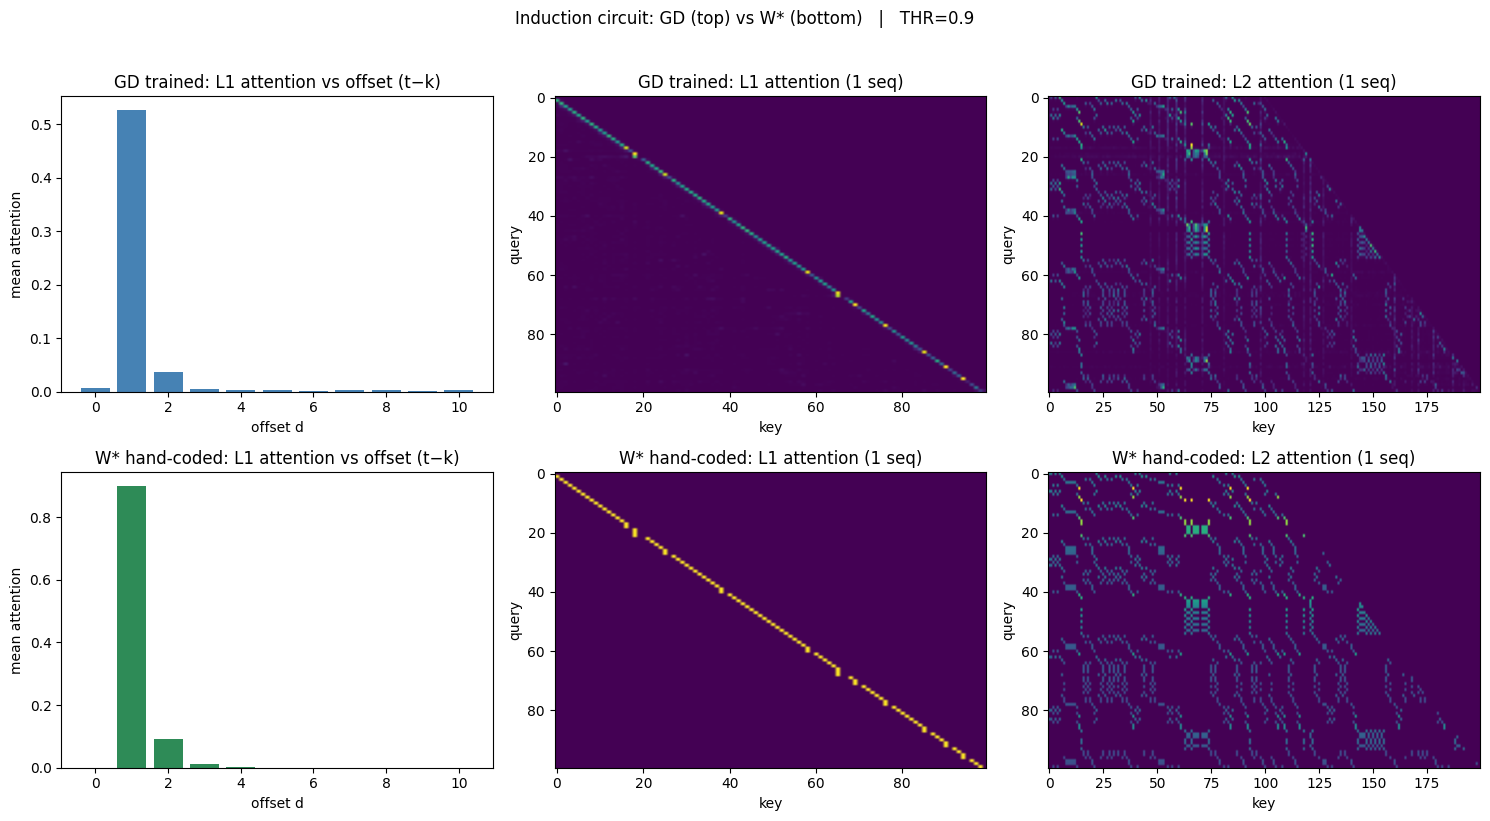

In [46]:
# ── Rung 2 (BEHAVIORAL): GD  vs  W*  — do both implement the induction circuit? ─
# Top row = GD trained model;  bottom row = W* hand-construction  (same THR).
@torch.no_grad()
def attentions(model, x, is_ws=False):
    """Return (A1, A2) softmax attention maps [B,T,T] for either model."""
    if not is_ws:                                   # DisentangledTransformer returns raw scores
        _, (a1, a2) = model(x, return_attn=True)
        return F.softmax(a1, -1).cpu().numpy(), F.softmax(a2, -1).cpu().numpy()
    B, T = x.shape                                  # W* exposes no attn → replay its forward pass
    tok = F.one_hot(x, V).float()
    pos = F.one_hot(torch.arange(T, device=x.device), seq_len).float().unsqueeze(0).expand(B, T, -1)
    s = torch.cat([tok, pos], -1)
    mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
    As = []
    for layer in (model.layer1, model.layer2):
        Q, K, Vv = layer.W_q(s), layer.W_k(s), layer.W_v(s)
        sc = torch.bmm(Q, K.transpose(1, 2)) / (layer.output_dim ** 0.5) + mask
        A = F.softmax(sc, -1); As.append(A.cpu().numpy())
        s = torch.cat([s, layer.W_o(torch.bmm(A, Vv))], -1)
    return As

xb = x_c.numpy()
def offset_profile(A1, maxoff=10):                  # layer-1: mean attention vs offset (t-k)
    off = np.zeros(maxoff + 1)
    for t in range(TOKEN_START, TOKEN_END):
        for d in range(maxoff + 1):
            if t - d >= 0: off[d] += A1[:, t, t - d].mean()
    return off / (TOKEN_END - TOKEN_START)
def induction_mass(A2):                             # layer-2: mass on keys whose prev tok == current
    m = 0.0; n = 0
    for t in range(TOKEN_START, TOKEN_END):
        if t < 2: continue
        match = (xb[:, 0:t - 1] == xb[:, t:t + 1]).astype(float)
        m += (A2[:, t, 1:t] * match).sum(1).mean(); n += 1
    return m / n

si = 0
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (name, model, is_ws, col) in enumerate(
        [('GD trained', gd_model, False, 'steelblue'),
         ('W* hand-coded', ws_model, True, 'seagreen')]):
    A1, A2 = attentions(model, x_c.to(device), is_ws)
    off = offset_profile(A1); mass = induction_mass(A2)
    print(f'{name:14s}  layer-1 peak offset = {off.argmax()}   layer-2 induction mass = {mass:.3f}')
    ax[row, 0].bar(range(len(off)), off, color=col)
    ax[row, 0].set_title(f'{name}: L1 attention vs offset (t−k)')
    ax[row, 0].set_xlabel('offset d'); ax[row, 0].set_ylabel('mean attention')
    ax[row, 1].imshow(A1[si, TOKEN_START:TOKEN_END, TOKEN_START:TOKEN_END], aspect='auto', cmap='viridis')
    ax[row, 1].set_title(f'{name}: L1 attention (1 seq)'); ax[row, 1].set_xlabel('key'); ax[row, 1].set_ylabel('query')
    ax[row, 2].imshow(A2[si, TOKEN_START:TOKEN_END, :TOKEN_END], aspect='auto', cmap='viridis')
    ax[row, 2].set_title(f'{name}: L2 attention (1 seq)'); ax[row, 2].set_xlabel('key'); ax[row, 2].set_ylabel('query')
plt.suptitle(f'Induction circuit: GD (top) vs W* (bottom)   |   THR={THR}', y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

GD trained      pos-pos band (offset 0..5) = [-0.   4.3  1.3  0.1 -0.5 -0.5]   signal perm-asymmetry = 0.085
W* hand-coded   pos-pos band (offset 0..5) = [  nan  -20.  -40.  -60.  -80. -100.]   signal perm-asymmetry = nan


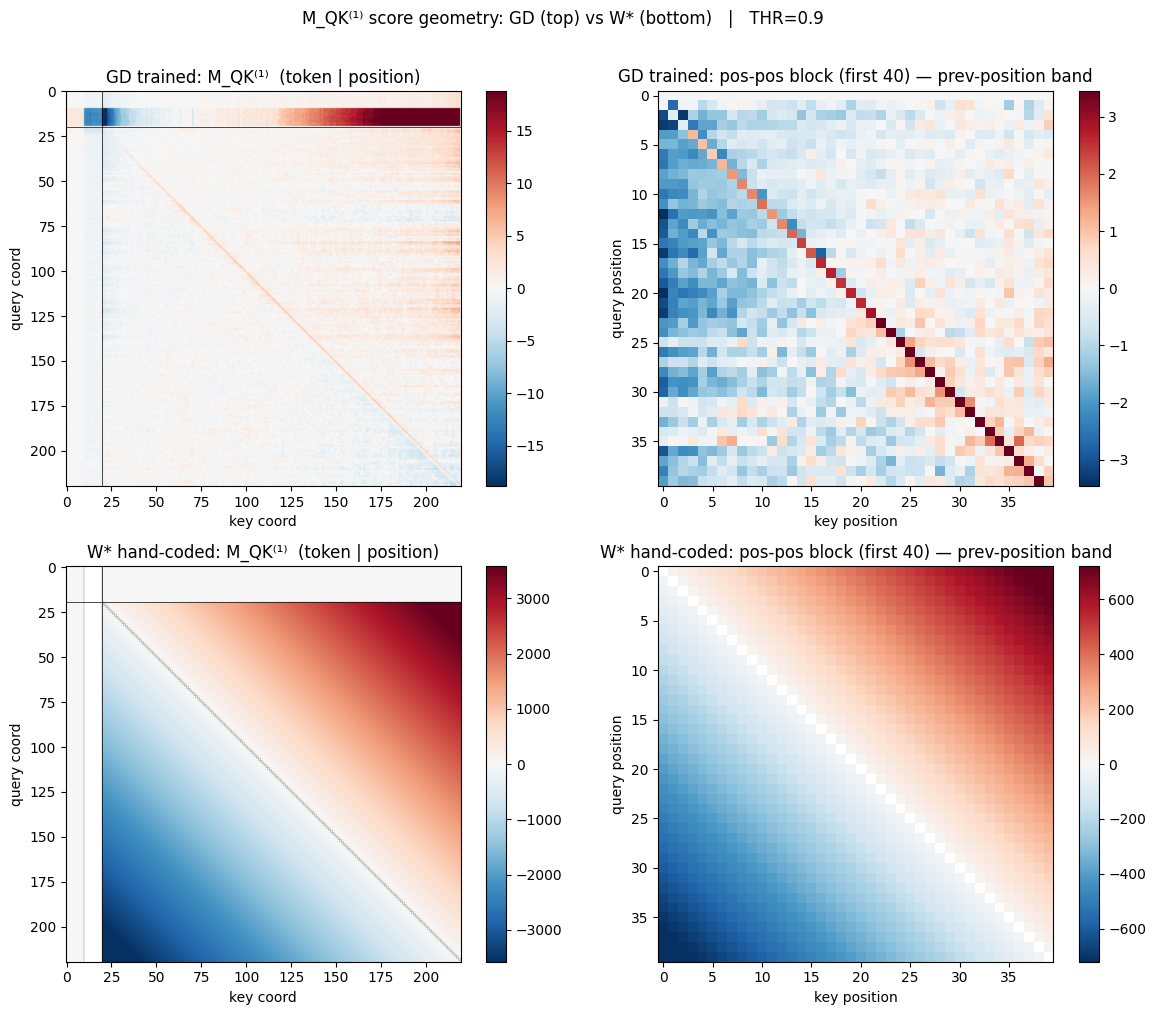

In [47]:
# ── Rung 3 (STRUCTURAL): GD vs W* — gauge-invariant M_QK⁽¹⁾ side by side ───────
# Top row = GD;  bottom row = W*.  Note: W* uses hard ±1e9 "logic gates"; we mask
# those (|x|>1e6 → NaN, shown white) so the meaningful structure is visible, and
# give each panel its own robust colour scale (magnitudes are not comparable, the
# *pattern* is — that's the gauge/implementation-freedom point).
import warnings
def MQK(blk):
    D = blk.W_q.weight.shape[0]
    return (blk.W_q.weight.t() @ blk.W_k.weight / (D ** 0.5)).detach().cpu().numpy()
def view(M):
    M = M.copy(); M[np.abs(M) > 1e6] = np.nan; return M    # hide hard gates

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for row, (name, model) in enumerate([('GD trained', gd_model), ('W* hand-coded', ws_model)]):
    mqk = MQK(model.layer1); pp = mqk[V:, V:]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')                    # offset-0 diagonal is all-NaN for W*
        band = [np.nanmean(np.diagonal(view(pp), offset=-d)) for d in range(6)]
    tt = mqk[:V_sig, :V_sig]; nrm = np.linalg.norm(tt)
    if nrm > 0:
        diag = np.mean(np.diag(tt)); offm = (tt.sum() - np.trace(tt)) / (V_sig * (V_sig - 1))
        recon = np.full_like(tt, offm); np.fill_diagonal(recon, diag)
        asym = np.linalg.norm(tt - recon) / nrm
    else:
        asym = float('nan')                                # W*: signal block is identically 0
    print(f'{name:14s}  pos-pos band (offset 0..5) = {np.round(band, 1)}   '
          f'signal perm-asymmetry = {asym:.3f}')

    Mv = view(mqk); q = np.nanpercentile(np.abs(Mv), 99)
    im0 = ax[row, 0].imshow(Mv, cmap='RdBu_r', vmin=-q, vmax=q)
    ax[row, 0].axhline(V - .5, color='k', lw=.5); ax[row, 0].axvline(V - .5, color='k', lw=.5)
    ax[row, 0].set_title(f'{name}: M_QK⁽¹⁾  (token | position)')
    ax[row, 0].set_xlabel('key coord'); ax[row, 0].set_ylabel('query coord')
    plt.colorbar(im0, ax=ax[row, 0], fraction=.046)

    ppv = view(pp)[:40, :40]; q2 = np.nanpercentile(np.abs(ppv), 99)
    im1 = ax[row, 1].imshow(ppv, cmap='RdBu_r', vmin=-q2, vmax=q2)
    ax[row, 1].set_title(f'{name}: pos-pos block (first 40) — prev-position band')
    ax[row, 1].set_xlabel('key position'); ax[row, 1].set_ylabel('query position')
    plt.colorbar(im1, ax=ax[row, 1], fraction=.046)
plt.suptitle(f'M_QK⁽¹⁾ score geometry: GD (top) vs W* (bottom)   |   THR={THR}', y=1.01, fontsize=12)
plt.tight_layout(); plt.show()